In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv('car_price_prediction_data.csv')

print('=== DATASET OVERVIEW===')
print(f'Raw shape: {df.shape}')
print(f'Missing Values: {df.isnull().sum().sum()}')
print(f'Duplicate Rows: {df.duplicated().sum()}')

df_clean = df.drop_duplicates().copy()
print(f'Clean Shape: {df_clean.shape}\n')
print(df_clean.describe().round(2))

=== DATASET OVERVIEW===
Raw shape: (301, 9)
Missing Values: 0
Duplicate Rows: 2
Clean Shape: (299, 9)

          Year  Selling_Price  Present_Price  Driven_kms   Owner
count   299.00         299.00         299.00      299.00  299.00
mean   2013.62           4.59           7.54    36916.75    0.04
std       2.90           4.98           8.57    39015.17    0.25
min    2003.00           0.10           0.32      500.00    0.00
25%    2012.00           0.85           1.20    15000.00    0.00
50%    2014.00           3.51           6.10    32000.00    0.00
75%    2016.00           6.00           9.84    48883.50    0.00
max    2018.00          35.00          92.60   500000.00    3.00


In [3]:
# 2. FEATURE ENGINEERING & PREPROCESSING
# Convert manufacturing Year into Car_Age (dataset max year is 2018 -> reference 2019)
reference_year = df_clean['Year'].max() + 1
df_clean['Car_Age'] = reference_year - df_clean['Year']

# Drop high-cardinality Car_Name (98 unique names) & raw Year
X = df_clean.drop(columns=['Car_Name', 'Year', 'Selling_Price'])
X = pd.get_dummies(X, drop_first=True)
y = df_clean['Selling_Price']

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [4]:
# 3. MODEL COMPARISON: RAW TARGET VS. LOG-TRANSFORMED TARGET
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    'Gradient Boosting Regressor': GradientBoostingRegressor(
        n_estimators=200, random_state=42
    ),
}

print('\n=== MODEL PERFORMANCE: RAW SELLING PRICE ===')
for name, model in models.items():
  model.fit(X_train, y_train)
  preds = model.predict(X_test)
  print(
      f'{name:28s} | R2: {r2_score(y_test, preds):.4f} | '
      f'MAE: {mean_absolute_error(y_test, preds):.3f} | '
      f'RMSE: {np.sqrt(mean_squared_error(y_test, preds)):.3f}'
  )

print('\n=== MODEL PERFORMANCE: LOG-TRANSFORMED TARGET (log1p) ===')
y_train_log = np.log1p(y_train)
trained_log_models = {}

for name, model in models.items():
  model.fit(X_train, y_train_log)
  preds = np.expm1(model.predict(X_test))
  trained_log_models[name] = (model, preds)
  print(
      f'{name:28s} | R2: {r2_score(y_test, preds):.4f} | '
      f'MAE: {mean_absolute_error(y_test, preds):.3f} | '
      f'RMSE: {np.sqrt(mean_squared_error(y_test, preds)):.3f}'
  )


=== MODEL PERFORMANCE: RAW SELLING PRICE ===
Linear Regression            | R2: 0.7527 | MAE: 1.473 | RMSE: 2.525
Random Forest Regressor      | R2: 0.5215 | MAE: 1.471 | RMSE: 3.512
Gradient Boosting Regressor  | R2: 0.7334 | MAE: 1.201 | RMSE: 2.621

=== MODEL PERFORMANCE: LOG-TRANSFORMED TARGET (log1p) ===
Linear Regression            | R2: 0.9034 | MAE: 0.914 | RMSE: 1.578
Random Forest Regressor      | R2: 0.6480 | MAE: 1.322 | RMSE: 3.012
Gradient Boosting Regressor  | R2: 0.8398 | MAE: 0.968 | RMSE: 2.032


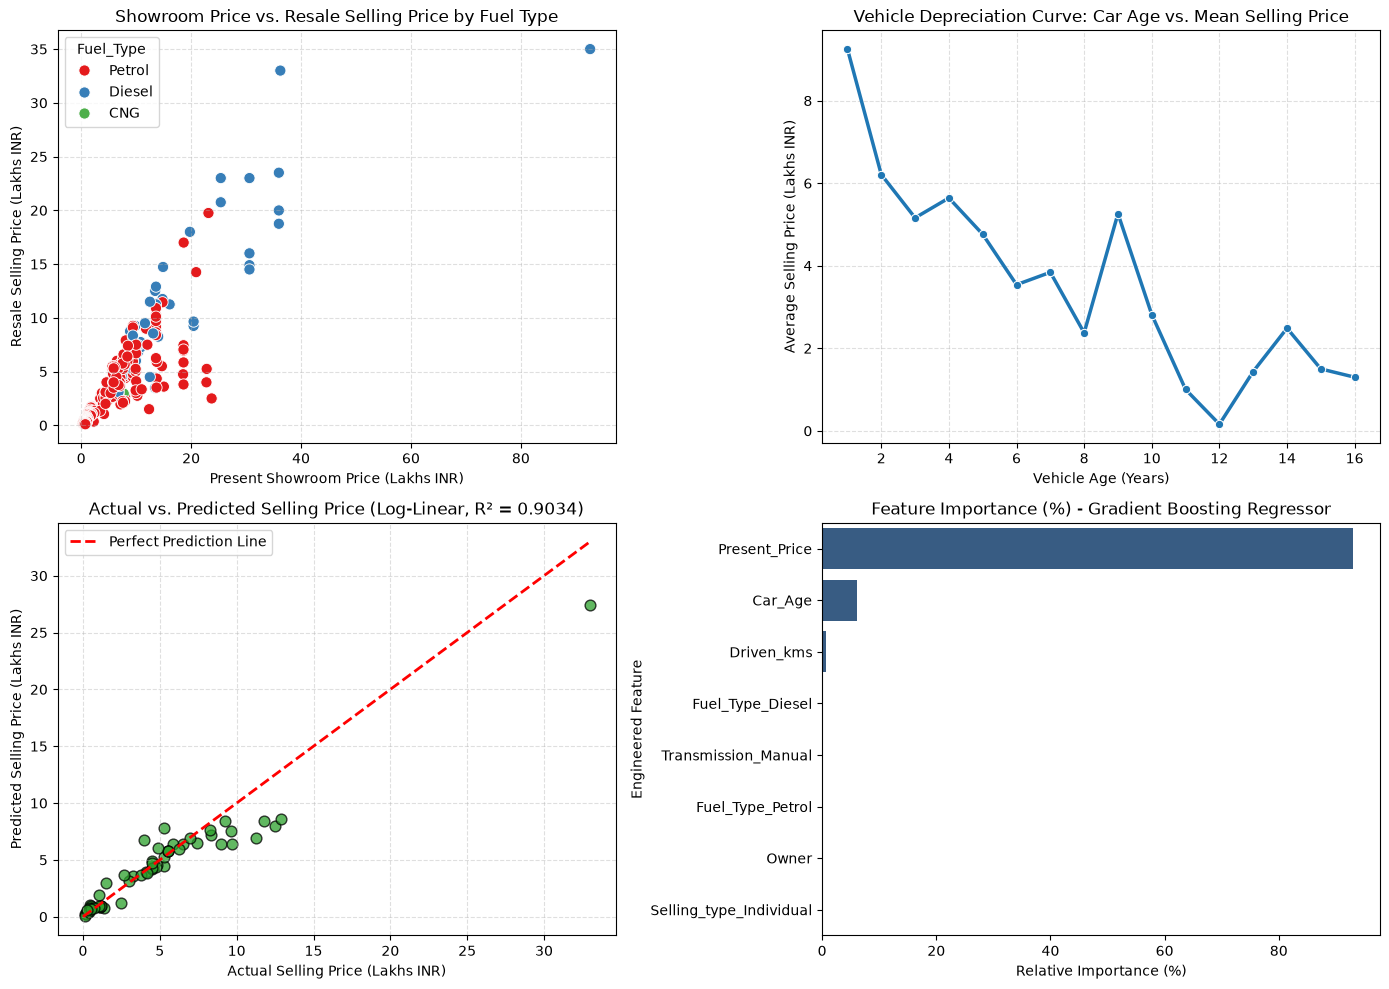

In [5]:
# 4. VISUALIZATIONS (4-PANEL DIAGNOSTIC DASHBOARD)
lr_model, y_pred_lr_log = trained_log_models['Linear Regression']
gb_model, y_pred_gb_log = trained_log_models['Gradient Boosting Regressor']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Showroom Price vs Resale Price by Fuel Type
sns.scatterplot(
    data=df_clean,
    x='Present_Price',
    y='Selling_Price',
    hue='Fuel_Type',
    palette='Set1',
    s=65,
    ax=axes[0, 0],
)
axes[0, 0].set_title('Showroom Price vs. Resale Selling Price by Fuel Type')
axes[0, 0].set_xlabel('Present Showroom Price (Lakhs INR)')
axes[0, 0].set_ylabel('Resale Selling Price (Lakhs INR)')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

# Panel 2: Vehicle Depreciation Curve
age_curve = df_clean.groupby('Car_Age')['Selling_Price'].mean().reset_index()
sns.lineplot(
    data=age_curve,
    x='Car_Age',
    y='Selling_Price',
    marker='o',
    color='#1f77b4',
    linewidth=2.5,
    ax=axes[0, 1],
)
axes[0, 1].set_title('Vehicle Depreciation Curve: Car Age vs. Mean Selling Price')
axes[0, 1].set_xlabel('Vehicle Age (Years)')
axes[0, 1].set_ylabel('Average Selling Price (Lakhs INR)')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)

# Panel 3: Actual vs Predicted Selling Price (Log-Linear Regression)
axes[1, 0].scatter(
    y_test, y_pred_lr_log, color='#2ca02c', alpha=0.75, edgecolors='k', s=60
)
max_val = max(y_test.max(), y_pred_lr_log.max())
axes[1, 0].plot(
    [0, max_val],
    [0, max_val],
    'r--',
    linewidth=2,
    label='Perfect Prediction Line',
)
axes[1, 0].set_title(
    'Actual vs. Predicted Selling Price (Log-Linear, R² = 0.9034)'
)
axes[1, 0].set_xlabel('Actual Selling Price (Lakhs INR)')
axes[1, 0].set_ylabel('Predicted Selling Price (Lakhs INR)')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

# Panel 4: Feature Importance (%)
gb_imp = pd.Series(
    gb_model.feature_importances_, index=X.columns
).sort_values(ascending=False)
sns.barplot(
    x=gb_imp.values * 100, y=gb_imp.index, color='#2b5c8f', ax=axes[1, 1]
)
axes[1, 1].set_title('Feature Importance (%) - Gradient Boosting Regressor')
axes[1, 1].set_xlabel('Relative Importance (%)')
axes[1, 1].set_ylabel('Engineered Feature')

plt.tight_layout()
plt.show()